# UMAP del conjunto de test

Se visualizan únicamente las imágenes con del conjunto de pruebas, `split == "test"`, en `metadata.csv` de `data/12.unificado_divididos_en_train_val_y_test`. Se respeta la división persistida, sin generar otra partición ni aplicar filtros adicionales por clase.

Se conservan los pesos locales de ResNet18 de `model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth`, el preprocesamiento y los parámetros de UMAP. Cada imagen se representa mediante las 512 características de `avgpool`. UMAP se ajusta solo con los vectores de test y sin etiquetas.

La misma proyección se muestra por clase, por origen del recorte (tope/base) y por porcentaje de perfil conservado.

## Configuración

In [1]:
from dataclasses import asdict

import matplotlib.pyplot as plt
from IPython.display import display
from torch.utils.data import DataLoader

from vasijas.config import load_config
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)
from vasijas.umap_evaluacion import (
    ConfiguracionUmap,
    DatasetTestConRuta,
    cargar_resnet18_entrenada,
    crear_extractor_resnet18,
    extraer_caracteristicas_por_lotes,
    contar_imagenes_por_grupo,
    graficar_umap_por_origen,
    graficar_umap_por_porcentaje,
    graficar_umap_test,
    guardar_resultado_umap,
    guardar_vistas_adicionales_umap,
    imprimir_archivos_generados,
    imprimir_resumen_fracciones,
    obtener_limites_grafico_umap,
    obtener_muestra_metadata,
    obtener_muestra_resultado_umap,
    preparar_datos_vistas_fracciones,
    proyectar_caracteristicas_umap,
    seleccionar_metadata,
    validar_caracteristicas_resnet18,
    validar_columnas_metadata,
    validar_metadata,
    validar_metadata_resultado_umap,
    validar_orden_rutas_extraidas,
)

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO
MODEL_PATH = (
    PATHS.OUTPUT_MODELS / "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
)
OUTPUT_DIR = PATHS.OUTPUT_UMAP
CSV_PATH = OUTPUT_DIR / f"umap_unificado_{MODEL_PATH.stem}.csv"
FIGURE_PATH = OUTPUT_DIR / f"umap_unificado_{MODEL_PATH.stem}.png"

CONJUNTOS = ["test"]
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
UMAP_CONFIG = ConfiguracionUmap(
    n_neighbors=50,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
DEVICE = seleccionar_dispositivo_procesamiento()

print(f"metadata: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print(f"conjuntos: {', '.join(CONJUNTOS)}")
print(f"modelo: {MODEL_PATH.name}")
print(f"dispositivo: {DEVICE}")
print(f"batch_size: {BATCH_SIZE}")
print(f"tamano_imagen: {TAMANO_IMAGEN}")
for parametro, valor in asdict(UMAP_CONFIG).items():
    print(f"{parametro}: {valor}")

metadata: data\12.unificado_divididos_en_train_val_y_test\metadata.csv
conjuntos: test
modelo: model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
dispositivo: cpu
batch_size: 16
tamano_imagen: 224
n_neighbors: 50
min_dist: 0.1
metric: cosine
random_state: 42


## Preparación de los datos

Se seleccionan exclusivamente las filas con los datos de prueba.

Los identificadores o rutas duplicados, los campos de identidad faltantes y las imágenes inexistentes detienen el proceso.

El preprocesamiento es de 224 × 224 y normalización ImageNet, sin aumentación.

In [3]:
metadata_split = cargar_metadata(DATA_DIR)
columnas_requeridas = {"Identificador", "ruta_relativa", "clase_carpeta", "split"}
validar_columnas_metadata(metadata_split, columnas_requeridas)

metadata = seleccionar_metadata(metadata_split, conjuntos=CONJUNTOS)
validar_metadata(metadata, columnas_requeridas, DATA_DIR, conjuntos=CONJUNTOS)

metadata_imagenes = metadata.copy()
resumen_conjuntos = contar_imagenes_por_grupo(metadata_split, "split")
resumen_clases = contar_imagenes_por_grupo(
    metadata_imagenes, "clase_carpeta", nombre_conteo="imagenes_seleccionadas"
)
muestra_metadata = obtener_muestra_metadata(metadata_imagenes, cantidad=5)

display(resumen_conjuntos)
display(resumen_clases)
display(muestra_metadata)
print(
    f"Total de imágenes seleccionadas referenciadas y encontradas: {len(metadata_imagenes)}"
)
print(f"Valores faltantes en Clase Ana: {metadata_imagenes['Clase Ana'].isna().sum()}")

,imagenes
split,
test,3059
train,14231
val,3059


,imagenes_seleccionadas
clase_carpeta,
clase01,76
clase02,133
clase03,209
clase05,152
clase06,152
clase07,133
clase08,798
clase09,57
clase10,1007


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,archivo,ruta_relativa,clase_carpeta,split
0,al_03b,No,II,1,B,2,2,11.0,178,57,46,ibero,Almedinilla,al_03b,completo,100.0,al_03b.png,clase11/al_03b.png,clase11,test
1,al_03f,No,II,1,B,9,2,11.0,178,54,35,ibero,Almedinilla,al_03f,completo,100.0,al_03f.png,clase11/al_03f.png,clase11,test
2,al_05a,No,II,11,B,2,2,10.0,240,47,67,ibero,Almedinilla,al_05a,completo,100.0,al_05a.png,clase10/al_05a.png,clase10,test
3,al_05h,No,II,11,B,2,2,10.0,156,60,73,ibero,Almedinilla,al_05h,completo,100.0,al_05h.png,clase10/al_05h.png,clase10,test
4,al_05l,No,II,11,B,2,2,10.0,84,36,32,ibero,Almedinilla,al_05l,completo,100.0,al_05l.png,clase10/al_05l.png,clase10,test


Total de imágenes seleccionadas referenciadas y encontradas: 3059
Valores faltantes en Clase Ana: 0


In [4]:
transformacion_evaluacion = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)[2]
dataset_imagenes = DatasetTestConRuta(
    metadata_imagenes, DATA_DIR, transformacion_evaluacion
)
loader_imagenes = DataLoader(
    dataset_imagenes,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
print(f"Imágenes: {len(dataset_imagenes)} · Lotes: {len(loader_imagenes)}")

Imágenes: 3059 · Lotes: 192


## Extracción de características

Se reconstruye la misma ResNet18 a partir de sus pesos locales, sin descargar pesos. La cantidad de salidas del clasificador se lee del archivo del modelo. Se extraen únicamente las características anteriores al clasificador, en modo evaluación y sin gradientes.

Se verifica un vector por imagen de test, incluido el último lote incompleto. Los vectores quedan en memoria para repetir UMAP con otros parámetros.

In [5]:
modelo = cargar_resnet18_entrenada(MODEL_PATH, DEVICE)
extractor = crear_extractor_resnet18(modelo)

caracteristicas, rutas_extraidas = extraer_caracteristicas_por_lotes(
    extractor, loader_imagenes, DEVICE
)
validar_orden_rutas_extraidas(rutas_extraidas, metadata_imagenes)
validar_caracteristicas_resnet18(caracteristicas, len(metadata))

metadata_caracteristicas = metadata_imagenes.copy()
print(f"Matriz de características verificada: {caracteristicas.shape}")

Características: 1600/3059
Características: 3059/3059
Matriz de características verificada: (3059, 512)


## 1. Proyección y visualización por clase

Se ajusta UMAP exclusivamente sobre los vectores de test, con distancia coseno, semilla fija y un solo trabajo para reproducir el ajuste en el mismo entorno. Las clases y demás columnas de metadata no intervienen en el ajuste; las clases solo se usan para colorear los puntos. Se verifica que todas las filas pertenezcan al split test.

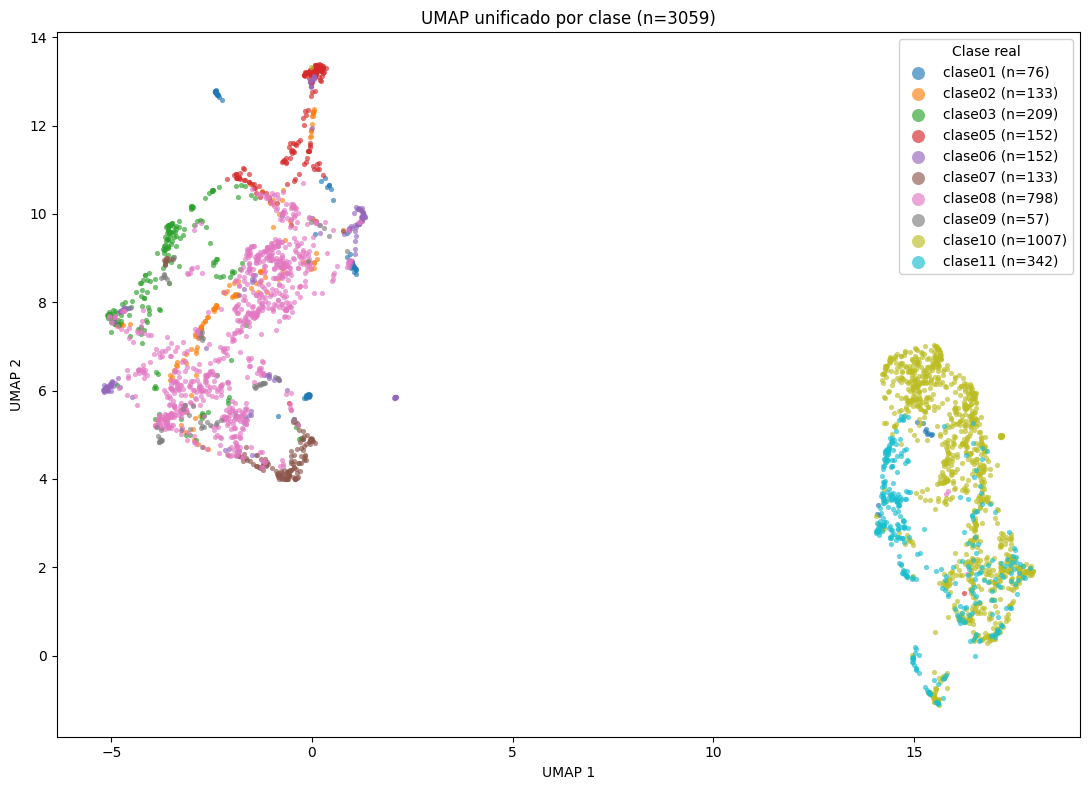

In [6]:
tabla_umap = proyectar_caracteristicas_umap(
    caracteristicas, metadata_caracteristicas, UMAP_CONFIG, conjuntos=CONJUNTOS
)
figura_umap = graficar_umap_test(
    tabla_umap,
    posicion_leyenda="interior",
    titulo=f"UMAP unificado por clase (n={len(tabla_umap)})",
)
display(figura_umap)
plt.close(figura_umap)

In [7]:
origen, porcentaje, fracciones = preparar_datos_vistas_fracciones(
    tabla_umap, conjuntos=CONJUNTOS
)
limites_x, limites_y = obtener_limites_grafico_umap(figura_umap)
imprimir_resumen_fracciones(origen, descripcion_conjunto="seleccionadas")

completo: 161 imágenes seleccionadas
tope: 1449 imágenes seleccionadas
base: 1449 imágenes seleccionadas
Fracciones: 2898 · Total: 3059


## 2. Fracciones por origen: tope y base

Solo se representan los recortes de test: **tope (borde) en naranja** y **base en azul**. Las imágenes completas se excluyen únicamente de esta vista. Se conservan las coordenadas y límites del gráfico por clase, sin volver a ajustar UMAP. La leyenda interna indica el número de fracciones por grupo.

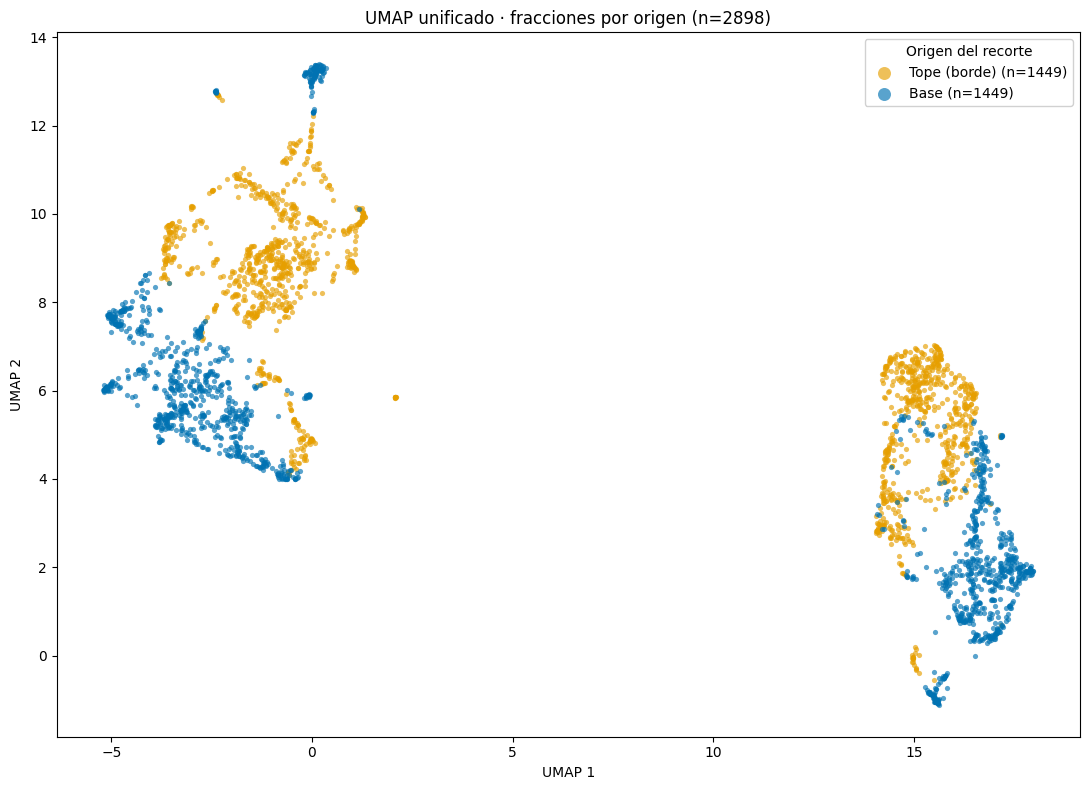

In [8]:
figura_origen = graficar_umap_por_origen(
    tabla_umap,
    origen,
    limites_x,
    limites_y,
    titulo=f"UMAP unificado · fracciones por origen (n={len(fracciones)})",
)
display(figura_origen)
plt.close(figura_origen)

## 3. Porcentaje conservado: escala de azules

Incluye todas las imágenes de test, con las mismas coordenadas y límites. La escala va de 0 a 100 %: cuanto más perfil conserva la imagen, más oscuro es el azul; las completas tienen el tono más oscuro. Se dibujan primero los porcentajes menores para que las completas queden visibles donde se superponen puntos.

El porcentaje representa la proporción de perfil conservada, no el área o la cantidad de píxeles. Un mismo porcentaje desde el tope y desde la base recibe el mismo tono.

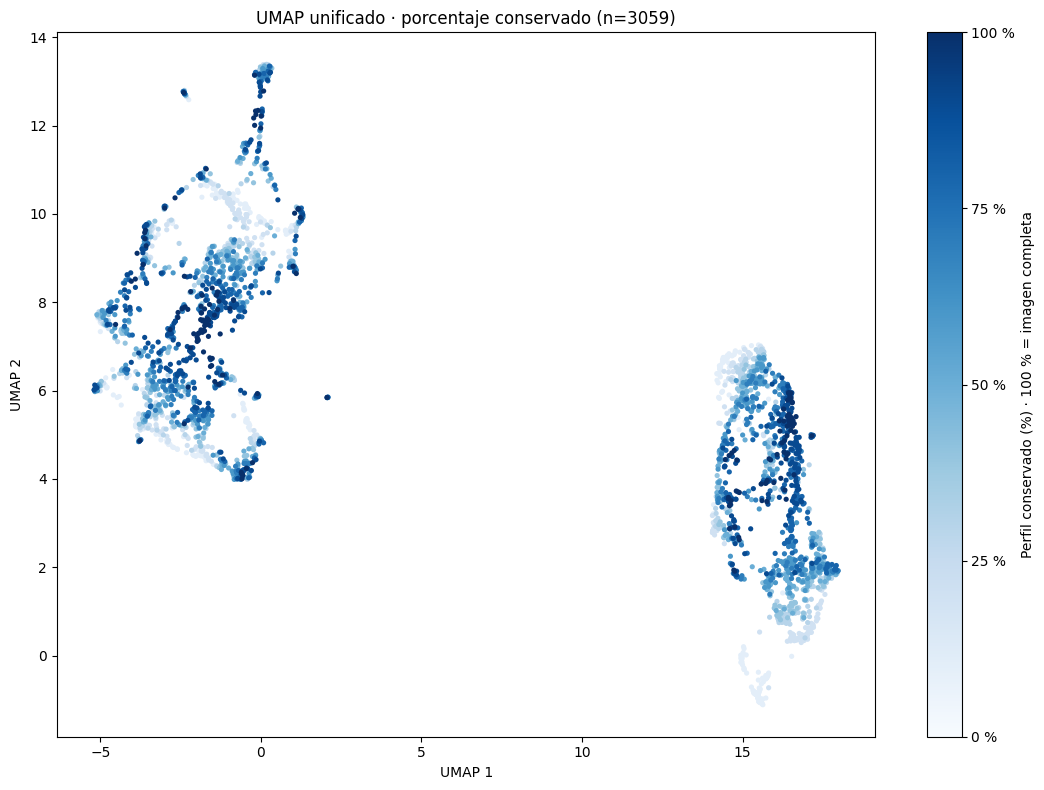

In [9]:
figura_porcentaje = graficar_umap_por_porcentaje(
    tabla_umap,
    porcentaje,
    limites_x,
    limites_y,
    titulo=f"UMAP unificado · porcentaje conservado (n={len(tabla_umap)})",
)
display(figura_porcentaje)
plt.close(figura_porcentaje)

## Exportación

El CSV conserva todas las filas de test y sus columnas originales, sus valores faltantes y su orden; agrega las coordenadas `UMAP_1` y `UMAP_2`. Se guardan las tres figuras mostradas en PNG a 200 dpi en `output/umap/`: por clase (`umap_test_`), origen (`umap_test_origen_fracciones_`) y porcentaje (`umap_test_porcentaje_`).

In [10]:
validar_metadata_resultado_umap(tabla_umap, metadata)
rutas_guardadas = guardar_resultado_umap(
    tabla=tabla_umap,
    figura=figura_umap,
    ruta_csv=CSV_PATH,
    ruta_figura=FIGURE_PATH,
)

muestra_resultado = obtener_muestra_resultado_umap(tabla_umap, cantidad=10)
display(muestra_resultado)
imprimir_archivos_generados(rutas_guardadas)

rutas_vistas_adicionales = guardar_vistas_adicionales_umap(
    [
        ("origen_fracciones", figura_origen),
        ("porcentaje", figura_porcentaje),
    ],
    directorio_salida=OUTPUT_DIR,
    ruta_modelo=MODEL_PATH,
    prefijo="umap_unificado",
)
imprimir_archivos_generados(rutas_vistas_adicionales)

,Identificador,ruta_relativa,clase_carpeta,split,UMAP_1,UMAP_2
0,al_03b,clase11/al_03b.png,clase11,test,14.563013,3.581655
1,al_03f,clase11/al_03f.png,clase11,test,14.597668,2.877112
2,al_05a,clase10/al_05a.png,clase10,test,16.444324,5.326818
3,al_05h,clase10/al_05h.png,clase10,test,16.524151,5.389168
4,al_05l,clase10/al_05l.png,clase10,test,16.428186,5.449188
5,al_06e,clase10/al_06e.png,clase10,test,16.306782,4.865412
6,al_06j,clase10/al_06j.png,clase10,test,17.154200,4.977540
7,al_07f,clase06/al_07f.png,clase06,test,-1.196539,6.350379
8,al_07h,clase07/al_07h.png,clase07,test,-0.455018,4.239109
9,al_09a,clase11/al_09a.png,clase11,test,14.728063,1.936878


Archivo generado: output\umap\umap_unificado_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv
Archivo generado: output\umap\umap_unificado_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
Archivo generado: output\umap\umap_unificado_origen_fracciones_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
Archivo generado: output\umap\umap_unificado_porcentaje_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
